# Appointment no-shows in Brazil

## Introduction

Why are some medical appointments missed? This report looks at how missed
appointments differ by patient age, the number of days between booking and the
appointment, and whether a text message was recorded.

The data contains 110,527 appointments in Brazil, dated April 29 to June 8,
2016. Each row is one appointment, so a patient can appear more than once.
The results describe patterns in these records; they do not tell us what
caused a patient to miss an appointment.

### Questions

The analysis follows four questions. Each comparison looks at the percentage
of appointments missed, rather than just the number missed.

1. Which age groups missed a larger share of their appointments?
2. Were appointments booked further in advance missed more often?
3. How did missed appointments differ between records with and without a text message?
4. Does the message comparison change when appointments have similar booking
   delays? How do age and booking delay look together?

### Report navigation

- [Data description and setup](#data-description)
- [Data wrangling](#data-wrangling)
- [Exploratory data analysis](#exploratory-data-analysis)
- [Conclusions](#conclusions)
- [Limitations](#limitations)

<a id="data-description"></a>
### Data description

This section explains the columns used in the report. A text message is called
an **SMS** in the dataset and in the chart labels.

The attendance column needs care: **`No-show = Yes` means the patient missed
the appointment; `No` means the patient attended.** A no-show rate of 20%
means that 20 out of every 100 appointments were missed.

| Source field | Meaning and use |
|---|---|
| PatientId | Identifies a patient, who may have several appointments |
| AppointmentID | Identifies an appointment; used to check for duplicates |
| Gender | Recorded gender; not one of the three main comparisons |
| ScheduledDay | Timestamp when the appointment was scheduled |
| AppointmentDay | Appointment date; the time of day is not supplied |
| Age | Recorded age in years, including infants aged zero |
| Neighbourhood | Recorded clinic/appointment neighbourhood |
| Scholarship | Recorded welfare-program enrollment indicator |
| Hipertension | Whether hypertension was recorded; this is the source column's spelling |
| Diabetes | Whether diabetes was recorded |
| Alcoholism | Whether alcoholism was recorded |
| Handcap | Recorded disability level; this field has more than two possible values |
| SMS_received | 1 means an SMS was recorded; 0 means it was not |
| No-show | Recorded attendance label: Yes = missed, No = attended |

The analysis uses the appointment file supplied with the project. The
[original dataset description](https://www.kaggle.com/datasets/joniarroba/noshowappointments)
provides more background on the fields.

In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 115, 'font.size': 10, 'axes.titlesize': 12,
    'axes.labelsize': 10, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
DATA = Path('data/noshowappointments-kagglev2-may-2016.csv')
# Stop if the input differs from the snapshot used for the report's findings.
EXPECTED_SHA256 = '9132d3e7d0246617df9041d3764f20ad6f08e7b0d9f0997fa254fc5e52eda27d'
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == EXPECTED_SHA256
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | matplotlib {matplotlib.__version__}')
print('Supplied dataset checksum verified.')

Python 3.13.5 | pandas 3.1.0 | NumPy 2.5.4 | matplotlib 3.11.2
Supplied dataset checksum verified.


<a id="data-wrangling"></a>
## Data Wrangling

Before comparing appointments, check that the records can be used reliably.
This section looks for missing values, duplicates and dates or ages that do
not make sense, then explains the cleaning decisions.

### Inspect before changing data

The first checks show the size of the dataset and the values in each column.
Patient and appointment IDs are left out of the preview because their actual
values are not needed to understand the comparisons.

In [2]:
# IDs are labels, not measurements; keep them as text to avoid numeric conversion.
raw = pd.read_csv(DATA, dtype={'PatientId': 'string', 'AppointmentID': 'string'})
print('Rows and columns:', raw.shape)
display(raw.drop(columns=['PatientId', 'AppointmentID']).head())
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(),
                      'distinct': raw.nunique(dropna=False)}))
# Check the original age range and spread before deciding which values are invalid.
display(raw[['Age', 'SMS_received']].describe())
print('Exact duplicate rows:', int(raw.duplicated().sum()))
print('Duplicate appointment IDs:', int(raw['AppointmentID'].duplicated().sum()))
# Repeated patients are expected and must not be removed as duplicate appointments.
print('Unique patient identifiers:', raw['PatientId'].nunique())
print("Additional rows after each patient's first appointment:", int(raw['PatientId'].duplicated().sum()))
display(raw['No-show'].value_counts().rename('appointments').to_frame())

Rows and columns: (110527, 14)


,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


,dtype,missing,distinct
PatientId,string,0,62299
AppointmentID,string,0,110527
Gender,str,0,2
ScheduledDay,str,0,103549
AppointmentDay,str,0,27
Age,int64,0,104
Neighbourhood,str,0,81
Scholarship,int64,0,2
Hipertension,int64,0,2
Diabetes,int64,0,2


,Age,SMS_received
count,110527.000000,110527.000000
mean,37.088874,0.321026
std,23.110205,0.466873
min,-1.000000,0.000000
25%,18.000000,0.000000
50%,37.000000,0.000000
75%,55.000000,1.000000
max,115.000000,1.000000


Exact duplicate rows: 0
Duplicate appointment IDs: 0
Unique patient identifiers: 62299
Additional rows after each patient's first appointment: 48228


,appointments
No-show,
No,88208
Yes,22319


### Cleaning decisions

The checks found no missing values or duplicate appointments. Two kinds of
record could not be used in the comparisons:

- One record had a negative age.
- Five records put the appointment date before the booking date.

These six records are removed. Missing values are not filled in, and no other
appointments are removed. The count table below shows the effect of each step.

### Measuring the booking delay

Booking delay means the number of calendar days from booking to the
appointment. If both happened on the same date, the delay is zero.

The appointment's time of day is not available. Comparing dates, rather than
exact hours, avoids treating an afternoon booking as later than a same-day
appointment stored with a midnight timestamp.

### Keeping age and repeat visits

Age zero is kept because the data includes infants. High ages, including 115,
are also kept because there is no supporting information to correct them.

A patient can have several real appointments. Those visits are kept because
this report counts appointments, not people. Column names are shortened for
readability; the recorded disability levels are kept as supplied.

In [3]:
SOURCE_COLUMNS = {'PatientId': 'patient_id',
 'AppointmentID': 'appointment_id',
 'Gender': 'gender',
 'ScheduledDay': 'scheduled_day',
 'AppointmentDay': 'appointment_day',
 'Age': 'age',
 'Neighbourhood': 'neighbourhood',
 'Scholarship': 'scholarship',
 'Hipertension': 'hypertension',
 'Diabetes': 'diabetes',
 'Alcoholism': 'alcoholism',
 'Handcap': 'handicap_level',
 'SMS_received': 'sms_received',
 'No-show': 'no_show_label'}

def clean_appointments(raw):
    """Return one row per usable appointment and sequential exclusion counts."""
    required = {"PatientId", "AppointmentID", "Age", "ScheduledDay",
                "AppointmentDay", "SMS_received", "No-show"}
    if not required.issubset(raw.columns):
        raise ValueError(f"Missing required columns: {sorted(required - set(raw.columns))}")
    labels = set(raw["No-show"].dropna().unique())
    if not labels.issubset({"Yes", "No"}):
        raise ValueError(f"Unexpected No-show labels: {labels}")

    df = raw.rename(columns=SOURCE_COLUMNS).copy()
    audit = [{"rule": "Input appointments", "removed": 0, "remaining": len(df)}]

    def exclude(mask, reason):
        nonlocal df
        removed = int(mask.sum())
        df = df.loc[~mask].copy()
        audit.append({"rule": reason, "removed": removed, "remaining": len(df)})

    # Deduplicate appointments, not patients: one person can have several visits.
    exclude(df.duplicated(), "Exact duplicate rows")
    if df["appointment_id"].duplicated().any():
        raise ValueError("Conflicting duplicate appointment IDs require investigation")
    # Unparseable values become missing so the audit records their removal.
    for column in ["scheduled_day", "appointment_day"]:
        df[column] = pd.to_datetime(df[column], utc=True, errors="coerce")
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    df["sms_received"] = pd.to_numeric(df["sms_received"], errors="coerce")
    critical = ["patient_id", "appointment_id", "age", "scheduled_day",
                "appointment_day", "sms_received", "no_show_label"]
    exclude(df[critical].isna().any(axis=1), "Missing or unparseable critical fields")
    if not df["sms_received"].isin([0, 1]).all():
        raise ValueError("Unexpected SMS_received values")
    # Age zero includes infants; only negative ages are invalid here.
    exclude(df["age"] < 0, "Negative ages")

    # Appointment timestamps omit appointment time; compare encoded calendar dates.
    df["waiting_days"] = (
        df["appointment_day"].dt.normalize() - df["scheduled_day"].dt.normalize()
    ).dt.days
    exclude(df["waiting_days"] < 0, "Appointment precedes scheduling date")
    # The source label is easy to reverse: Yes means the appointment was missed.
    df["no_show"] = df["no_show_label"].eq("Yes")
    # Left-closed bands put age 18 in 18-34, not in the under-18 group.
    df["age_band"] = pd.cut(
        df["age"], [0, 18, 35, 50, 65, np.inf], right=False,
        labels=["Under 18", "18-34", "35-49", "50-64", "65+"],
    )
    # Keep same-day bookings separate from appointments booked further ahead.
    df["waiting_band"] = pd.cut(
        df["waiting_days"], [-1, 0, 7, 14, 30, 60, np.inf],
        labels=["Same day", "1-7 days", "8-14 days", "15-30 days", "31-60 days", "61+ days"],
    )
    df["sms_group"] = pd.Categorical(
        df["sms_received"].map({0: "No SMS recorded", 1: "SMS recorded"}),
        categories=["No SMS recorded", "SMS recorded"], ordered=True,
    )
    return df.reset_index(drop=True), pd.DataFrame(audit)


def group_rates(df, columns):
    """Keep denominators alongside observed group rates; empty groups stay absent."""
    # A Boolean mean is the missed share; counts show how many visits it describes.
    # observed=True avoids reporting a rate for a group with no appointments.
    result = df.groupby(columns, observed=True, dropna=False)["no_show"].agg(
        appointments="size", no_shows="sum", no_show_rate="mean",
    )
    return result.assign(no_show_pct=lambda x: 100 * x["no_show_rate"])


def label_plot(ax, title, xlabel, ylabel):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    return ax


def show_rates(table):
    columns = {'appointments': 'Appointments', 'no_shows': 'Missed appointments',
               'no_show_pct': 'Missed (%)'}
    display(table[list(columns)].rename(columns=columns).round(2))

print('Data checks and chart helpers are ready.')

Data checks and chart helpers are ready.


In [4]:
# Reconcile exclusions with the input count before using the cleaned appointments.
appointments, cleaning_audit = clean_appointments(raw)
display(cleaning_audit)
assert len(raw) - cleaning_audit['removed'].sum() == len(appointments)
assert appointments['appointment_id'].is_unique
assert appointments['age'].ge(0).all() and appointments['waiting_days'].ge(0).all()
assert not appointments[['age_band', 'waiting_band', 'sms_group']].isna().any().any()
print('Appointments after cleaning:', len(appointments))
print('Unique patients:', appointments['patient_id'].nunique())
print('Appointment dates:', appointments['appointment_day'].min().date(), 'to', appointments['appointment_day'].max().date())
# Mean and median describe the center; standard deviation describes the spread.
display(appointments[['age', 'waiting_days']].agg(['min', 'median', 'mean', 'std', 'max']).rename(
    index={'min': 'Smallest', 'median': 'Middle value', 'mean': 'Average',
           'std': 'Standard deviation', 'max': 'Largest'},
    columns={'age': 'Age (years)', 'waiting_days': 'Booking delay (days)'}
).round(2))
display(appointments[['gender', 'age', 'waiting_days', 'sms_group', 'no_show']].head())

,rule,removed,remaining
0,Input appointments,0,110527
1,Exact duplicate rows,0,110527
2,Missing or unparseable critical fields,0,110527
3,Negative ages,1,110526
4,Appointment precedes scheduling date,5,110521


Appointments after cleaning: 110521


Unique patients: 62298
Appointment dates: 2016-04-29 to 2016-06-08


,Age (years),Booking delay (days)
Smallest,0.00,0.00
Middle value,37.00,4.00
Average,37.09,10.18
Standard deviation,23.11,15.26
Largest,115.00,179.00


,gender,age,waiting_days,sms_group,no_show
0,F,62,0,No SMS recorded,False
1,M,56,0,No SMS recorded,False
2,F,62,0,No SMS recorded,False
3,F,8,0,No SMS recorded,False
4,F,56,0,No SMS recorded,False


### Data used in the analysis

The cleaning leaves **110,521 appointments for
62,298 patients**. Of these appointments,
**22,314 were missed (20.19%)**.

That is about one missed appointment in every five. This overall percentage
is the starting point for the age, booking-delay and message comparisons below.

The middle booking delay was 4 days, while the
average was 10.2 days. Some long delays pull the
average above the middle value. The standard deviation was
15.3 days; it measures how widely the delays varied
around the average, not how accurately the average is known.

<a id="exploratory-data-analysis"></a>
## Exploratory Data Analysis

This section compares the three patient and appointment details with missed
visits. For each question, a table shows the number of appointments and the
percentage missed, followed by charts and a short explanation.

### 1. Age and appointment attendance

Start by looking at the ages in the records, then compare the percentage of
appointments missed by each age group. This matters because a large age group
could have many missed appointments without having a high percentage missed.

,appointments
no_show,
Attended,88207
Missed,22314


,Appointments,Missed appointments,Missed (%)
Age group,,,
Under 18,27378,5996,21.90
18-34,24244,5812,23.97
35-49,21864,4489,20.53
50-64,22634,3785,16.72
65+,14401,2232,15.50


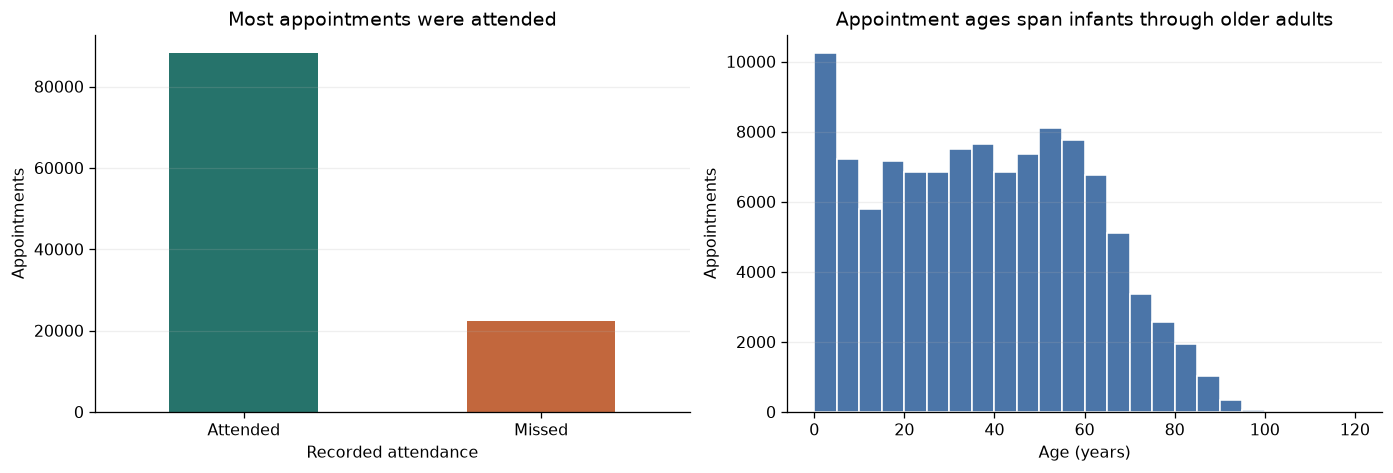

In [5]:
# Keep group sizes alongside rates so larger groups do not appear worse just by size.
overall_pct = 100 * appointments['no_show'].mean()
outcome_counts = appointments['no_show'].map({False: 'Attended', True: 'Missed'}).value_counts().reindex(['Attended', 'Missed'])
display(outcome_counts.rename('appointments').to_frame())
age_rates = group_rates(appointments, 'age_band')
show_rates(age_rates.rename_axis('Age group'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
outcome_counts.plot.bar(ax=axes[0], color=['#26736b', '#c2673d'], rot=0)
label_plot(axes[0], 'Most appointments were attended', 'Recorded attendance', 'Appointments')
# Five-year bins show the age distribution without a separate bar for every age.
appointments['age'].plot.hist(ax=axes[1], bins=np.arange(0, 121, 5), color='#4b75a8', edgecolor='white')
label_plot(axes[1], 'Appointment ages span infants through older adults', 'Age (years)', 'Appointments')
fig.savefig(FIGURES / '01_outcome_and_age.png', bbox_inches='tight')
plt.show()

#### Compare the percentage missed in each age group

The age histogram shows which ages appear most often in the data. The next
chart answers a different question: what share of each age group's
appointments was missed? The dashed line shows the overall rate for comparison.

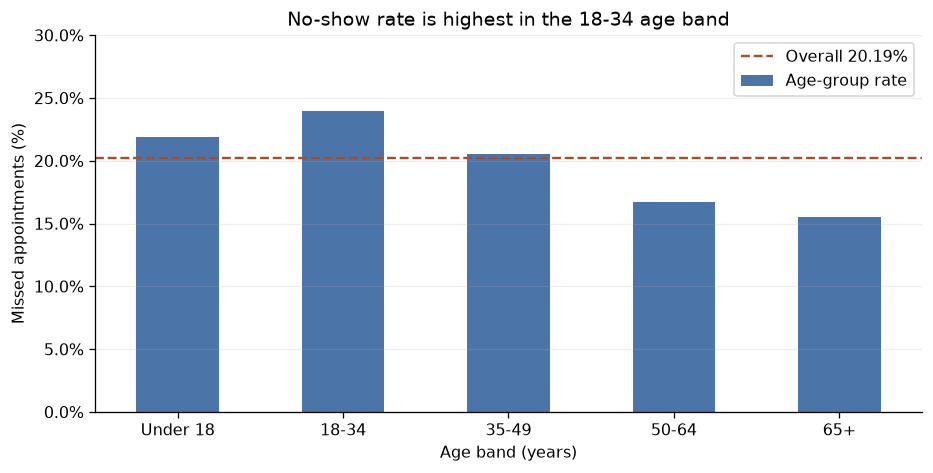

In [6]:
# Compare percentages across age groups; the dashed line is the overall benchmark.
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
age_rates['no_show_pct'].plot.bar(ax=ax, color='#4b75a8', rot=0, label='Age-group rate')
ax.axhline(overall_pct, color='#a54e2a', linestyle='--', label=f'Overall {overall_pct:.2f}%')
ax.set_ylim(0, 30)
ax.yaxis.set_major_formatter(PercentFormatter(100))
label_plot(ax, 'No-show rate is highest in the 18-34 age band', 'Age band (years)', 'Missed appointments (%)')
ax.legend()
fig.savefig(FIGURES / '02_age_rates.png', bbox_inches='tight')
plt.show()

#### What the age comparison shows

Appointments for people aged 18–34 had the highest missed-appointment rate,
at **23.97%**. The rate was
15.50% for ages 65 and above, and
21.90% for those under 18.

Young adults missed a larger share of their appointments than either children
or older adults in these records. This comparison does not explain why:
travel, work, medical needs and the time between booking and the appointment
may also differ between the age groups.

### 2. Days between booking and the appointment

Were appointments booked further in advance missed more often? The next
charts show how long those delays were and the percentage missed in each
group. Appointments booked for the same day are shown separately.

,Appointments,Missed appointments,Missed (%)
Days between booking and appointment,,,
Same day,38562,1792,4.65
1-7 days,32185,7772,24.15
8-14 days,12025,3664,30.47
15-30 days,17371,5661,32.59
31-60 days,8283,2829,34.15
61+ days,2095,596,28.45


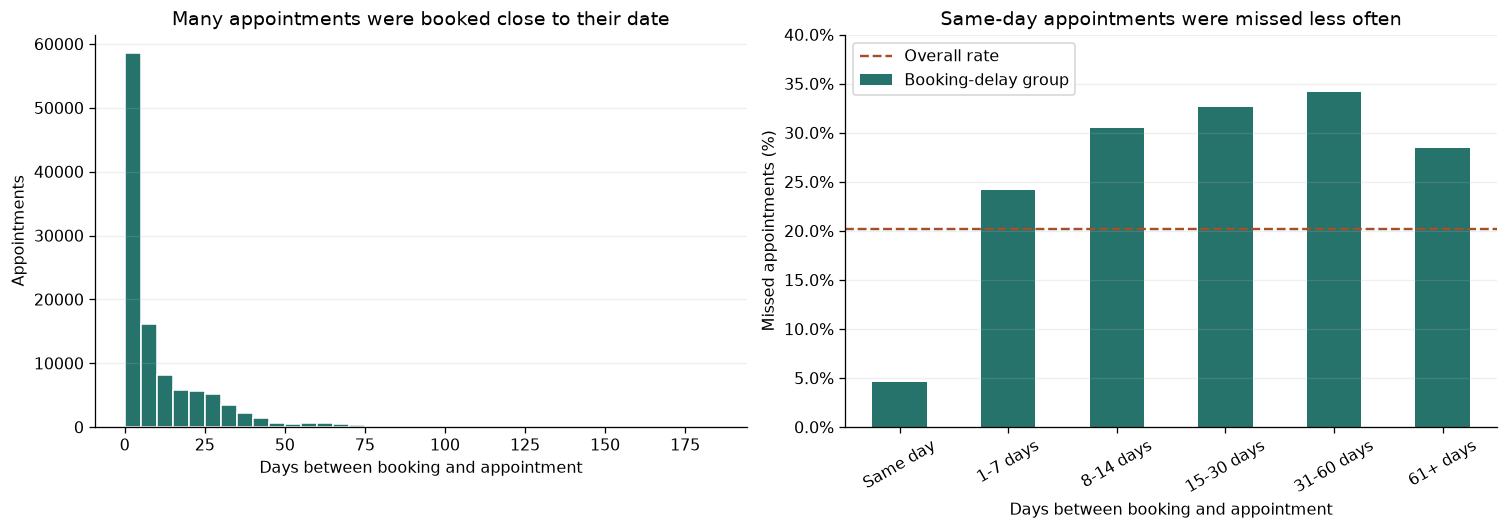

In [7]:
# Compare each booking-delay group's missed share, keeping same-day bookings separate.
waiting_rates = group_rates(appointments, 'waiting_band')
show_rates(waiting_rates.rename_axis('Days between booking and appointment'))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
# The histogram shows the long tail of delays; rate bars answer the attendance question.
appointments['waiting_days'].plot.hist(ax=axes[0], bins=np.arange(0, 186, 5), color='#26736b', edgecolor='white')
label_plot(axes[0], 'Many appointments were booked close to their date', 'Days between booking and appointment', 'Appointments')
waiting_rates['no_show_pct'].plot.bar(ax=axes[1], color='#26736b', rot=30, label='Booking-delay group')
axes[1].axhline(overall_pct, color='#a54e2a', linestyle='--', label='Overall rate')
axes[1].set_ylim(0, 40)
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
label_plot(axes[1], 'Same-day appointments were missed less often', 'Days between booking and appointment', 'Missed appointments (%)')
axes[1].legend()
fig.savefig(FIGURES / '03_lead_time.png', bbox_inches='tight')
plt.show()

#### What the booking-delay comparison shows

Only **4.65%** of same-day appointments were
missed. This compares with 24.15% for
appointments booked 1–7 days ahead and
34.15% for those booked 31–60 days ahead.

The rate then falls to 28.45% for delays of
61 days or more. It does not keep rising for every longer delay. These groups
may include different patients and appointment types, so the results do not
prove that shortening a delay would prevent a missed appointment.

### 3. Text messages and missed appointments

This comparison asks whether appointments with an SMS recorded were missed
more or less often than appointments without one. First check the size of
each group, then compare the percentage missed.

The records do not say when a message was sent, whether it was read, or why
some appointments received messages. The two groups were not set up as a fair
test of reminders.

,Appointments,Missed appointments,Missed (%)
Text-message record,,,
No SMS recorded,75039,12530,16.70
SMS recorded,35482,9784,27.57


,Middle booking delay (days),Average booking delay (days)
sms_group,,
No SMS recorded,0.0,6.01
SMS recorded,14.0,19.02


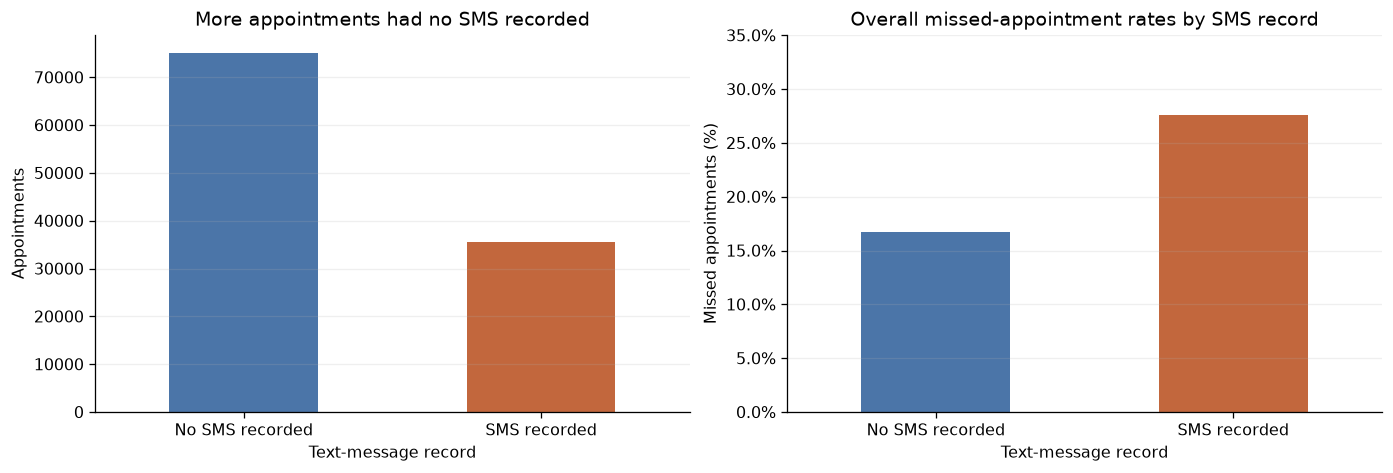

In [8]:
# Show both group size and missed percentage because the SMS groups are unequal.
sms_rates = group_rates(appointments, 'sms_group')
show_rates(sms_rates.rename_axis('Text-message record'))
# Booking delays may differ between these groups, so this is not a test of reminders.
display(appointments.groupby('sms_group', observed=True)['waiting_days'].agg(['median', 'mean']).rename(
    columns={'median': 'Middle booking delay (days)', 'mean': 'Average booking delay (days)'}
).round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
sms_rates['appointments'].plot.bar(ax=axes[0], rot=0, color=['#4b75a8', '#c2673d'])
label_plot(axes[0], 'More appointments had no SMS recorded', 'Text-message record', 'Appointments')
sms_rates['no_show_pct'].plot.bar(ax=axes[1], rot=0, color=['#4b75a8', '#c2673d'])
axes[1].set_ylim(0, 35)
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
label_plot(axes[1], 'Overall missed-appointment rates by SMS record', 'Text-message record', 'Missed appointments (%)')
fig.savefig(FIGURES / '04_sms_crude.png', bbox_inches='tight')
plt.show()

#### What the overall message comparison shows

The missed-appointment rate was **27.57%**
for the 35,482 appointments with an SMS
recorded. It was 16.70% for the
75,039 appointments without one.

This does **not** mean that messages made people miss appointments. The two
groups also differed in how far ahead appointments were booked. The next
comparison looks at that difference.

### 4. Compare appointments with similar booking delays

The overall SMS comparison mixes appointments with very different delays.
Here, the message groups are compared within the same delay ranges, such as
1–7 days or 8–14 days. This helps show whether their different booking delays
could explain part of the overall result.

The table gives the number of appointments as well as the percentage missed.
There are no same-day appointments with an SMS recorded, so that combination
has no percentage to plot. It should not be read as a zero missed-appointment
rate.

Appointments  Missed appointments  \
Booking-delay group Text-message record                                      
Same day            No SMS recorded             38562                 1792   
1-7 days            No SMS recorded             20637                 5028   
                    SMS recorded                11548                 2744   
8-14 days           No SMS recorded              5021                 1695   
                    SMS recorded                 7004                 1969   
15-30 days          No SMS recorded              6851                 2526   
                    SMS recorded                10520                 3135   
31-60 days          No SMS recorded              3224                 1237   
                    SMS recorded                 5059                 1592   
61+ days            No SMS recorded               744                  252   
                    SMS recorded                 1351                  344   

                                         Missed (%)  
Booking-delay group Text-message record              
Same day            No SMS recorded            4.65  
1-7 days            No SMS recorded           24.36  
                    SMS recorded              23.76  
8-14 days           No SMS recorded           33.76  
                    SMS recorded              28.11  
15-30 days          No SMS recorded           36.87  
                    SMS recorded              29.80  
31-60 days          No SMS recorded           38.37  
                    SMS recorded              31.47  
61+ days            No SMS recorded           33.87  
                    SMS recorded              25.46

sms_group,No SMS recorded,SMS recorded
waiting_band,,
Same day,38562.0,NaN
1-7 days,20637.0,11548.0
8-14 days,5021.0,7004.0
15-30 days,6851.0,10520.0
31-60 days,3224.0,5059.0
61+ days,744.0,1351.0


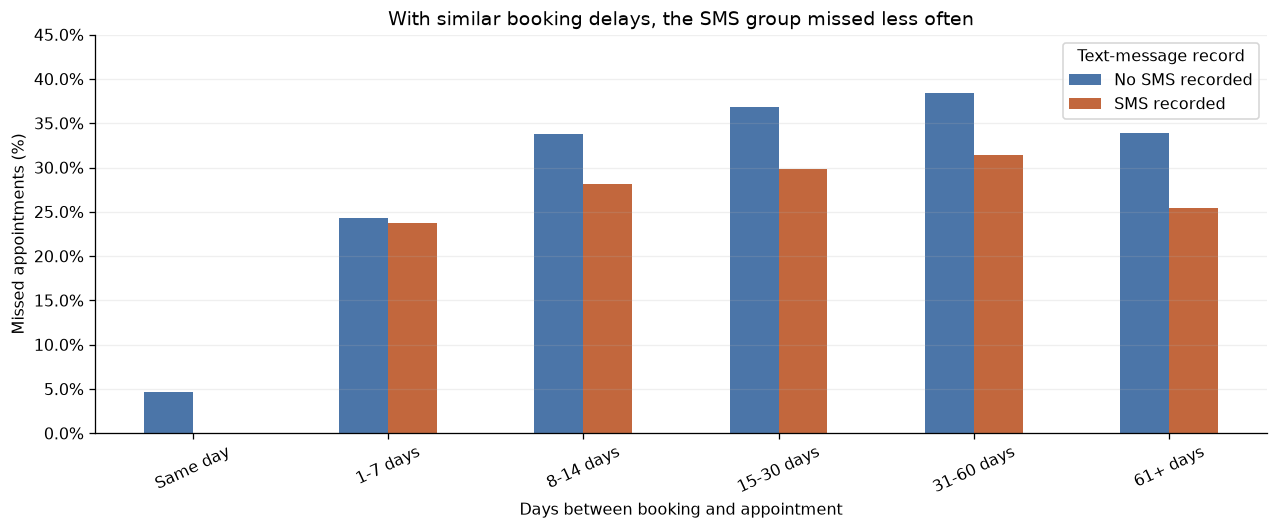

In [9]:
# Compare SMS groups within the same delay ranges rather than mixing all bookings.
sms_by_wait = group_rates(appointments, ['waiting_band', 'sms_group'])
show_rates(sms_by_wait.rename_axis(['Booking-delay group', 'Text-message record']))
# No same-day SMS appointments were observed; leave that rate missing, not zero.
rate_matrix = sms_by_wait['no_show_pct'].unstack('sms_group')
count_matrix = sms_by_wait['appointments'].unstack('sms_group')
display(count_matrix)
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
rate_matrix.plot.bar(ax=ax, rot=25, color=['#4b75a8', '#c2673d'])
ax.set_ylim(0, 45)
ax.yaxis.set_major_formatter(PercentFormatter(100))
label_plot(ax, 'With similar booking delays, the SMS group missed less often', 'Days between booking and appointment', 'Missed appointments (%)')
ax.legend(title='Text-message record')
fig.savefig(FIGURES / '05_sms_by_lead_time.png', bbox_inches='tight')
plt.show()

#### What changes when booking delay is considered

In all five delay ranges where both SMS groups appear, the SMS-recorded group
had a **lower** missed-appointment rate. This is the opposite of the overall
comparison. Same-day appointments help explain the difference: they had a low
missed-appointment rate, and none had an SMS recorded.

The message groups are still not identical. For example, they may differ in
age or appointment type, even within the same delay range. These results show
why comparing only the overall percentages can be misleading; they do not
tell us what the messages caused.

### Look at age and booking delay together

The final chart checks how both age and booking delay line up with missed
appointments. Each row is an age group and each column is a booking-delay
group. Darker cells mean a larger percentage of appointments were missed;
`n` gives the number of appointments in that cell.

Appointments  Missed appointments  Missed (%)
Age group Booking-delay group                                               
Under 18  Same day                    11212                  779        6.95
          1-7 days                     6201                 1667       26.88
          8-14 days                    3078                 1029       33.43
          15-30 days                   4337                 1525       35.16
          31-60 days                   2332                  904       38.77
          61+ days                      218                   92       42.20
18-34     Same day                     8534                  389        4.56
          1-7 days                     6534                 1942       29.72
          8-14 days                    2980                 1062       35.64
          15-30 days                   4135                 1595       38.57
          31-60 days                   1776                  705       39.70
          61+ days                      285                  119       41.75
35-49     Same day                     7615                  267        3.51
          1-7 days                     6362                 1620       25.46
          8-14 days                    2418                  722       29.86
          15-30 days                   3493                 1205       34.50
          31-60 days                   1636                  577       35.27
          61+ days                      340                   98       28.82
50-64     Same day                     6974                  245        3.51
          1-7 days                     7823                 1552       19.84
          8-14 days                    2188                  532       24.31
          15-30 days                   3310                  867       26.19
          31-60 days                   1695                  455       26.84
          61+ days                      644                  134       20.81
65+       Same day                     4227                  112        2.65
          1-7 days                     5265                  991       18.82
          8-14 days                    1361                  319       23.44
          15-30 days                   2096                  469       22.38
          31-60 days                    844                  188       22.27
          61+ days                      608                  153       25.16

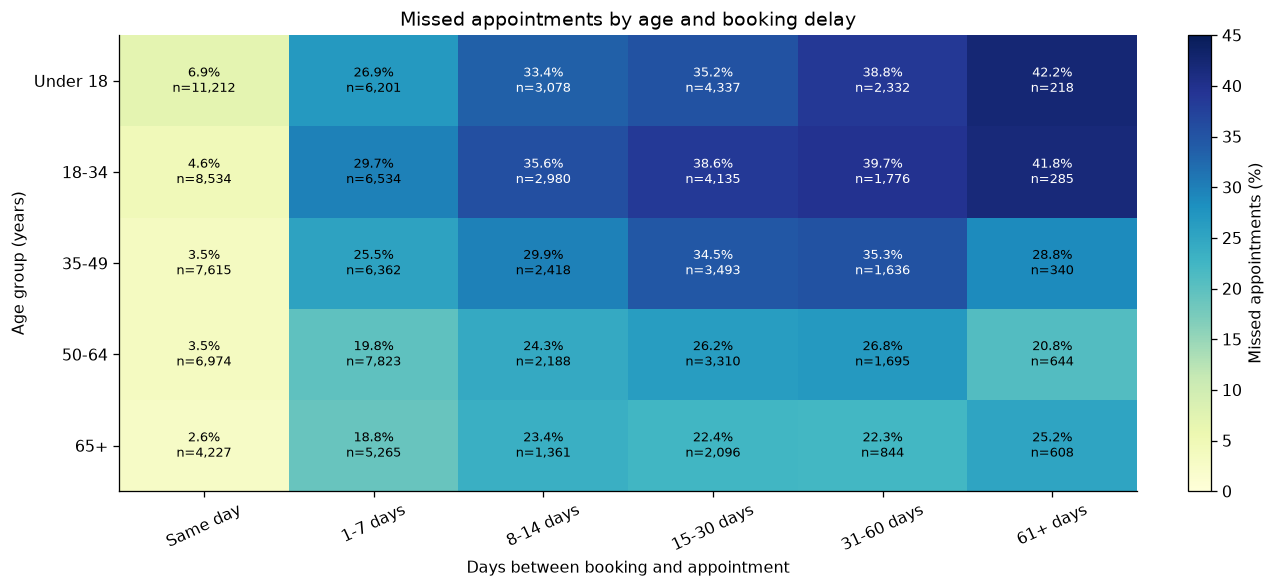

In [10]:
# A heatmap compares age and booking delay together without drawing many separate bars.
joint = group_rates(appointments, ['age_band', 'waiting_band'])
show_rates(joint.rename_axis(['Age group', 'Booking-delay group']))
joint_rates = joint['no_show_pct'].unstack('waiting_band')
joint_counts = joint['appointments'].unstack('waiting_band')
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
# Hide rates from groups below 100 appointments; their small counts could mislead.
shown = joint_rates.where(joint_counts >= 100)
image = ax.imshow(shown.to_numpy(), cmap='YlGnBu', vmin=0, vmax=45, aspect='auto')
ax.set_xticks(np.arange(len(shown.columns)), labels=shown.columns, rotation=25)
ax.set_yticks(np.arange(len(shown.index)), labels=shown.index)
# Include counts so the reader can see the number of appointments behind each rate.
for row in range(len(shown.index)):
    for col in range(len(shown.columns)):
        value = shown.iloc[row, col]
        n = joint_counts.iloc[row, col]
        label = f'{value:.1f}%\nn={int(n):,}' if pd.notna(value) else f'n={int(n):,} <100'
        ax.text(col, row, label, ha='center', va='center', fontsize=8,
                color='white' if pd.notna(value) and value > 30 else 'black')
label_plot(ax, 'Missed appointments by age and booking delay', 'Days between booking and appointment', 'Age group (years)')
ax.grid(False)
fig.colorbar(image, ax=ax, label='Missed appointments (%)')
fig.savefig(FIGURES / '06_age_by_lead_time.png', bbox_inches='tight')
plt.show()

#### What the age-and-delay chart shows

For every age group, same-day appointments had a lower missed-appointment
rate than appointments booked further ahead. For example, among people aged
18–34, the rates were about 4.6%
for same-day appointments and 39.7% for
appointments booked 31–60 days ahead.

The counts show which percentages come from smaller groups.

<a id="conclusions"></a>
## Conclusions

Of the 110,521 appointments used in the analysis,
**22,314 were missed (20.19%)**—about one in five.

### Age

People aged 18–34 missed a larger share of their appointments
(23.97%) than those aged 65 and above
(15.50%). The difference does not tell us why a
particular appointment was missed.

### Booking delay

Same-day appointments were missed much less often
(4.65%) than appointments booked 31–60 days
ahead (34.15%). The rate did not keep
rising for appointments booked furthest ahead.

### Text messages

Overall, the SMS-recorded group had a higher missed-appointment rate. But
within every booking-delay range where both groups appeared, it had a lower
rate. The overall numbers alone would therefore give an incomplete picture.

These comparisons do not establish that age, a longer delay or a message
caused a missed visit.

<a id="limitations"></a>
## Limitations

The records can show patterns, but they cannot answer every question about
missed appointments. The following limits matter when using the findings.

### Messages were not assigned at random

Patients with and without messages may have differed before any message was
sent. The records also do not say when messages arrived or whether they were
read. A difference between these groups is not enough to show that reminders
helped or harmed attendance.

### Appointments are not the same as patients

The 110,521 appointments came from 62,298
patients. A person with several appointments counts several times. The
percentages describe missed appointments, not the percentage of people who
missed a visit.

### The data covers a short period

These records cover April 29 to June 8, 2016, in the Brazilian appointment
data supplied for the project. The patterns may differ in other places or
today. A longer period would help show whether they stay similar over time.

### Important details are missing

The data does not explain travel difficulties, work commitments, appointment
purpose or why a visit was rescheduled. It also gives appointment dates
without times of day. These details could help explain missed appointments,
and grouping ages or delays into ranges cannot account for all of them.

## What to investigate next

A next study could record when reminders were sent, the type of appointment,
and cancellations or rescheduling. It could also look at each patient's
history rather than treating every visit as a separate comparison.

To find out whether reminders improve attendance, a study would need a fair
way to decide which appointments receive them. That question should be
answered before using these results to change reminder policies.

## Data source

The appointment data was supplied with Udacity's *Investigate a Dataset*
project. The course links to Joni Hoppen's *Medical Appointment No Shows*
dataset on Kaggle. The column descriptions above follow the information
provided with the project.